# Caffeine frontier molecular orbitals | CHPC CHEM1937
Reproduce the three-panel HOMO / energy levels / LUMO figure from the original ORCA 6.1.0 calculation (B3LYP-D3BJ/def2-TZVP). This notebook reads the supplied `caffeine_trj.zip`, not synthetic orbital data. Place the ZIP next to this notebook. Run all cells. Install dependencies in the same kernel if needed (`%pip install numpy matplotlib vtk`). Optional: `figentra` for your approved style; this environment uses explicitly recorded Matplotlib fallback settings. This is a new reproducible rendering implementation, not the original V3 source code.

In [1]:
from pathlib import Path
import zipfile, hashlib, re, itertools, importlib.metadata as metadata
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import vtk
from vtk.util.numpy_support import vtk_to_numpy, numpy_to_vtk
from IPython.display import display
from PIL import Image
from io import BytesIO

ARCHIVE = Path('caffeine_trj.zip')
OUT = Path('caffeine_figures'); OUT.mkdir(exist_ok=True)
ISO = 0.035  # orbital amplitude, atomic units
DPI = 450
print('Archive SHA256:', hashlib.sha256(ARCHIVE.read_bytes()).hexdigest())
for pkg in ['numpy','matplotlib','vtk','Pillow']:
    print(pkg, metadata.version(pkg))
z = zipfile.ZipFile(ARCHIVE)
print(z.namelist())

Archive SHA256: 5338966569cd6dc89c71595f8e56af07293c8fa23affacc214aa68657f8a8abb
numpy 2.3.5
matplotlib 3.10.8
vtk 9.6.2
Pillow 12.3.0
['caffeine_trj.xyz', 'caffeine.densities', 'caffeine.engrad', 'caffeine.mo51a.cube', 'Caffeine_DFT.o7659111', 'caffeine.bibtex', 'caffeine.opt', 'caffeine.gbw', 'caffeine.property.txt', 'caffeine.out', 'caffeine.inp', 'caffeine.pbs', 'caffeine.xyz', 'caffeine.mo50a.cube', 'caffeine.hess', 'caffeine.densitiesinfo']


## Parse and validate the final orbital-energy block
ORCA orbital indices are zero-based. The calculation is restricted closed shell; 51 doubly occupied orbitals correspond to 102 electrons. The Kohn–Sham gap is not an experimental optical gap.

In [2]:
out = z.read('caffeine.out').decode(errors='replace')
assert 'ORCA TERMINATED NORMALLY' in out
assert 'THE OPTIMIZATION HAS CONVERGED' in out
blocks = out.split('ORBITAL ENERGIES')
rows = []
for block in blocks[1:]:
    r = re.findall(r'^\s*(\d+)\s+(\d+\.\d+)\s+(-?\d+\.\d+)\s+(-?\d+\.\d+)\s*$', block, re.M)
    if r:
        rows = [(int(i),float(o),float(eh),float(ev)) for i,o,eh,ev in r]
homo = max((r for r in rows if r[1]>0),key=lambda r:r[0])
lumo = min((r for r in rows if r[1]==0 and r[0]>homo[0]),key=lambda r:r[0])
assert (homo[0],lumo[0]) == (50,51)
assert sum(r[1] for r in rows)==102
EH, EL = homo[3], lumo[3]; gap = EL-EH
print(f'HOMO {homo[0]}: {EH:.4f} eV; LUMO {lumo[0]}: {EL:.4f} eV; gap: {gap:.4f} eV')

HOMO 50: -6.1785 eV; LUMO 51: -1.0882 eV; gap: 5.0903 eV


## Read ORCA cube grids
The negative atom count indicates the additional orbital-index record. Coordinates and grid vectors are in bohr; the orbital amplitude is retained in atomic units. VTK expects x to vary fastest, so the array is flattened in Fortran order.

In [3]:
def read_cube(name, expected):
    lines = z.read(name).decode().splitlines()
    h=lines[2].split(); nat=abs(int(h[0])); origin=np.array(h[1:4],float)
    grid=[l.split() for l in lines[3:6]]
    dims=tuple(int(l[0]) for l in grid); axes=np.array([l[1:4] for l in grid],float)
    assert all(v>0 for v in dims) and np.allclose(axes,np.diag(np.diag(axes)))
    atoms=np.array([l.split() for l in lines[6:6+nat]],float)
    start=6+nat
    if int(h[0])<0:
        assert list(map(int,lines[start].split()))==[1,expected]; start+=1
    values=np.fromstring(' '.join(lines[start:]),sep=' ')
    assert values.size==np.prod(dims) and np.isfinite(values).all()
    image=vtk.vtkImageData(); image.SetDimensions(*dims); image.SetOrigin(*(origin*0.529177210903)); image.SetSpacing(*(np.diag(axes)*0.529177210903))
    image.GetPointData().SetScalars(numpy_to_vtk(values.reshape(dims).ravel(order='F'),deep=True))
    return image, atoms[:,0].astype(int),atoms[:,2:5]*0.529177210903
H, numbers, xyz=read_cube('caffeine.mo50a.cube',50)
L, nums2, xyz2=read_cube('caffeine.mo51a.cube',51)
assert np.array_equal(numbers,nums2) and np.allclose(xyz,xyz2)
print('Atoms:',len(numbers),'Grid:',H.GetDimensions())

Atoms: 24 Grid: (100, 100, 100)


## Render molecular geometry and signed orbital isosurfaces
Bonds are inferred from covalent radii and distances for visualization only. Identical camera, scale, opacity and isovalue are applied to both orbitals. Blue/red indicate wavefunction phase, not atomic charge.

In [4]:
colors={1:(.93,.93,.93),6:(.16,.17,.19),7:(.12,.25,.78),8:(.82,.08,.09)}
radii={1:.31,6:.76,7:.71,8:.66}
phase_colors={1:(.04,.25,.83),-1:(.83,.06,.09)}
center=xyz.mean(axis=0)

def actor(source,color,opacity=1):
    mapper=vtk.vtkPolyDataMapper(); mapper.SetInputConnection(source.GetOutputPort()); mapper.ScalarVisibilityOff()
    a=vtk.vtkActor(); a.SetMapper(mapper); prop=a.GetProperty(); prop.SetColor(*color); prop.SetOpacity(opacity); prop.SetSpecular(.3); prop.SetSpecularPower(25); return a

def render(grid):
    ren=vtk.vtkRenderer(); ren.SetBackground(1,1,1)
    for k,p in enumerate(xyz):
        s=vtk.vtkSphereSource(); s.SetCenter(*p); s.SetRadius(.12 if numbers[k]==1 else .22); s.SetThetaResolution(32); s.SetPhiResolution(32); ren.AddActor(actor(s,colors[numbers[k]]))
    for i,j in itertools.combinations(range(len(xyz)),2):
        if np.linalg.norm(xyz[i]-xyz[j]) < 1.22*(radii[numbers[i]]+radii[numbers[j]]) and not (numbers[i]==numbers[j]==1):
            mid=(xyz[i]+xyz[j])/2
            for k in [i,j]:
                line=vtk.vtkLineSource(); line.SetPoint1(*xyz[k]); line.SetPoint2(*mid)
                tube=vtk.vtkTubeFilter(); tube.SetInputConnection(line.GetOutputPort()); tube.SetRadius(.075); tube.SetNumberOfSides(24); tube.CappingOn(); ren.AddActor(actor(tube,colors[numbers[k]]))
    for sign,color in phase_colors.items():
        contour=vtk.vtkFlyingEdges3D(); contour.SetInputData(grid); contour.SetValue(0,sign*ISO); contour.ComputeNormalsOn(); ren.AddActor(actor(contour,color,.78))
    win=vtk.vtkRenderWindow(); win.SetOffScreenRendering(1); win.SetSize(1200,1200); win.AddRenderer(ren); win.SetMultiSamples(0)
    ren.SetUseDepthPeeling(1); ren.SetMaximumNumberOfPeels(100); win.SetAlphaBitPlanes(1)
    cam=ren.GetActiveCamera(); cam.SetFocalPoint(*center); cam.SetPosition(*(center+np.array([4,-7,18]))); cam.SetViewUp(0,1,0); cam.ParallelProjectionOn(); cam.SetParallelScale(4.5); ren.ResetCameraClippingRange()
    win.Render(); capture=vtk.vtkWindowToImageFilter(); capture.SetInput(win); capture.Update(); im=capture.GetOutput(); w,h,_=im.GetDimensions(); arr=vtk_to_numpy(im.GetPointData().GetScalars()).reshape(h,w,-1)[::-1].copy(); win.Finalize(); return arr
himg=render(H); limg=render(L)

2026-11-24 16:47:22.608 (   1.172s) [    7FBAF2A62780]vtkXOpenGLRenderWindow.:1460  WARN| bad X server connection. DISPLAY=:0


## Figure styling and export
Explicit fallback style: bold serif text, thick axes/ticks, white background, no grid. The Figentra package is optional and not required to reproduce these exact settings; do not claim its API was used. The same styling is applied on every run.

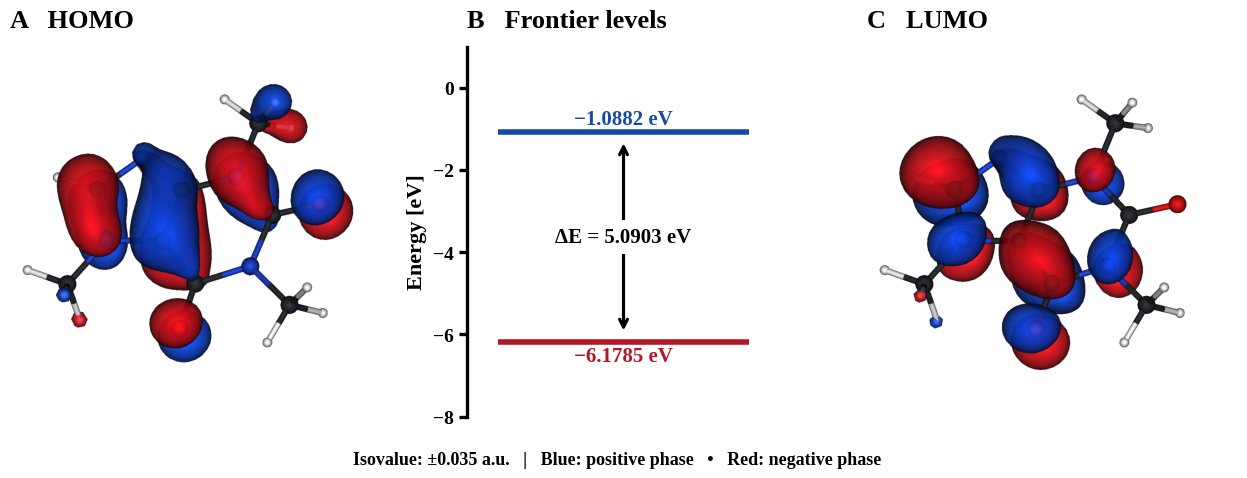

In [5]:
mpl.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Liberation Serif','DejaVu Serif'],'font.weight':'bold','axes.labelweight':'bold','axes.titleweight':'bold','axes.linewidth':2.4,'xtick.major.width':2.4,'ytick.major.width':2.4,'xtick.major.size':6,'ytick.major.size':6,'font.size':14,'figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white','pdf.fonttype':42})
fig,axs=plt.subplots(1,3,figsize=(13,5),gridspec_kw={'width_ratios':[1.1,.88,1.1]})
for ax,img,title in [(axs[0],himg,'A   HOMO'),(axs[2],limg,'C   LUMO')]:
    ax.imshow(img); ax.axis('off'); ax.set_title(title,loc='left',fontsize=19,pad=14)
a=axs[1]; a.set_title('B   Frontier levels',loc='left',fontsize=19,pad=14); a.set_ylim(-8,1); a.set_xlim(0,1); a.set_xticks([]); a.set_yticks([-8,-6,-4,-2,0]); a.set_ylabel('Energy [eV]',fontsize=16); a.spines[['top','right','bottom']].set_visible(False)
for y,c,dy in [(EH,'#b51625',-.36),(EL,'#174ba3',.32)]:
    a.hlines(y,.1,.9,color=c,lw=4); a.text(.5,y+dy,f'{y:.4f} eV'.replace('-','−'),ha='center',va='center',color=c,fontsize=15)
a.annotate('',xy=(.5,EL-.2),xytext=(.5,EH+.2),arrowprops={'arrowstyle':'<->','lw':2.3,'color':'black'}); a.text(.5,(EH+EL)/2,f'ΔE = {gap:.4f} eV',ha='center',va='center',fontsize=15,bbox={'facecolor':'white','edgecolor':'none','pad':5})
fig.subplots_adjust(left=.025,right=.985,bottom=.14,top=.88,wspace=.21); fig.text(.5,.045,f'Isovalue: ±{ISO:.3f} a.u.   |   Blue: positive phase   •   Red: negative phase',ha='center',fontsize=13)
for ext in ['png','pdf']:
    fig.savefig(OUT/f'caffeine_frontier_orbitals.{ext}',dpi=DPI,bbox_inches='tight',pad_inches=.12)
plt.show()